## Лабораторная работа №1. 
## Искусственные нейронные сети. Сети прямого распространения.

In [39]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from scikeras.wrappers import KerasClassifier
from sklearn.model_selection import GridSearchCV, train_test_split
import tensorflow as tf

from tensorflow.keras.datasets import mnist
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.losses import SparseCategoricalCrossentropy
from tensorflow.keras.models import Sequential
from sklearn.model_selection import train_test_split

IMAGE_SIZE = 28
NUM_CLASSES = 10
RANDOM_SEED = 42
VALIDATION_SIZE = 0.2

np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)

## Пункт 1. Подготовка данных

Набор данных **MNIST** содержит изображения рукописных цифр размером **28×28 пикселей**.

Для подачи изображений на вход полносвязной нейронной сети каждое изображение преобразуется в одномерный вектор длины **784 = 28×28**.

Значения интенсивности пикселей находятся в диапазоне **от 0 до 255**, поэтому перед обучением выполняется нормализация данных путём деления значений пикселей на **255**.

In [40]:
(x_train_full, y_train_full), (x_test, y_test) = mnist.load_data()

print(f"Обучающая выборка: {x_train_full.shape}")
print(f"Метки обучающей выборки: {y_train_full.shape}")
print(f"Тестовая выборка: {x_test.shape}")
print(f"Метки тестовой выборки: {y_test.shape}")

Обучающая выборка: (60000, 28, 28)
Метки обучающей выборки: (60000,)
Тестовая выборка: (10000, 28, 28)
Метки тестовой выборки: (10000,)


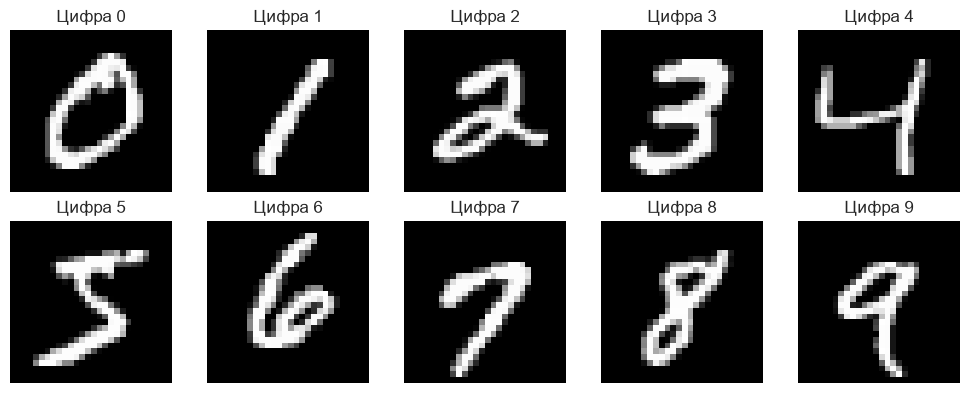

In [41]:
fig, axes = plt.subplots(nrows=2, ncols=5, figsize=(10, 4))

for digit, ax in enumerate(axes.flat):
    first_image_index = np.where(y_train_full == digit)[0][0]

    ax.imshow(x_train_full[first_image_index], cmap="gray")
    ax.set_title(f"Цифра {digit}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [42]:
x_train_full = x_train_full.astype(np.float32) / 255.0
x_test = x_test.astype(np.float32) / 255.0

input_size = IMAGE_SIZE * IMAGE_SIZE

x_train_full = x_train_full.reshape(x_train_full.shape[0], input_size)
x_test = x_test.reshape(x_test.shape[0], input_size)

x_train, x_val, y_train, y_val = train_test_split(
    x_train_full,
    y_train_full,
    test_size=VALIDATION_SIZE,
    random_state=RANDOM_SEED,
    shuffle=True,
    stratify=y_train_full,
)

print(f"Обучающая выборка: {x_train.shape}, {y_train.shape}")
print(f"Валидационная выборка: {x_val.shape}, {y_val.shape}")
print(f"Тестовая выборка: {x_test.shape}, {y_test.shape}")

Обучающая выборка: (48000, 784), (48000,)
Валидационная выборка: (12000, 784), (12000,)
Тестовая выборка: (10000, 784), (10000,)


## Пункт 2. Построение нейронной сети

Реализуем функцию построения полносвязной нейронной сети с возможностью задавать:

- один или два скрытых слоя;
- количество нейронов в каждом скрытом слое;
- значение `dropout`.

В скрытых слоях используется функция активации **ReLU**. Выходной слой содержит **10 нейронов** — по одному для каждого класса цифр от 0 до 9 — и использует функцию активации **softmax**.

In [43]:
def build_model(hidden_units=(128,), dropout_rate=0.0):
    model = Sequential()

    model.add(Input(shape=(input_size,)))

    for units in hidden_units:
        model.add(Dense(units, activation="relu"))

        if dropout_rate > 0:
            model.add(Dropout(dropout_rate))

    model.add(Dense(NUM_CLASSES, activation="softmax"))

    return model

### Базовая конфигурация модели

В качестве базовой модели используем нейронную сеть со следующими параметрами:

- один скрытый слой;
- 96 нейронов в скрытом слое;
- `dropout = 0.2`;
- 10 нейронов в выходном слое.

In [44]:
base_model = build_model(
    hidden_units=(96,),
    dropout_rate=0.2,
)

base_model.summary()

Model: "sequential_32"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_65 (Dense)                │ (None, 96)             │        75,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_28 (Dropout)            │ (None, 96)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_66 (Dense)                │ (None, 10)             │           970 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 76,330 (298.16 KB)

 Trainable params: 76,330 (298.16 KB)

 Non-trainable params: 0 (0.00 B)

## Пункт 3. Обучение базовой модели

Обучим базовую модель в течение **15 эпох** с размером пакета `batch_size = 64`.

Параметр `batch_size = 64` означает, что при обучении данные обрабатываются группами по 64 изображения, после чего выполняется очередное обновление весов нейронной сети.

In [45]:
base_model.compile(
    optimizer="adam",
    loss=SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

history = base_model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=15,
    batch_size=64,
    verbose=1,
)

Epoch 1/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8845 - loss: 0.4028 - val_accuracy: 0.9421 - val_loss: 0.2076
Epoch 2/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9427 - loss: 0.1999 - val_accuracy: 0.9542 - val_loss: 0.1576
Epoch 3/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9550 - loss: 0.1527 - val_accuracy: 0.9601 - val_loss: 0.1329
Epoch 4/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9640 - loss: 0.1228 - val_accuracy: 0.9638 - val_loss: 0.1189
Epoch 5/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9675 - loss: 0.1085 - val_accuracy: 0.9689 - val_loss: 0.1062
Epoch 6/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9713 - loss: 0.0937 - val_accuracy: 0.9702 - val_loss: 0.0998
Epoch 7/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9737 - loss: 0.0843 - val_accuracy: 0.9729 - val_loss: 0.0951
Epoch 8/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9760 - loss: 0.0764 - val_accuracy: 0.

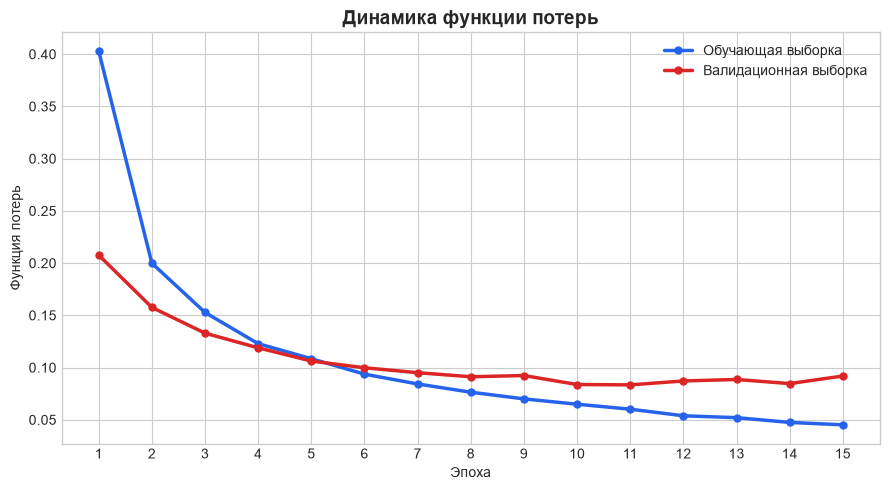

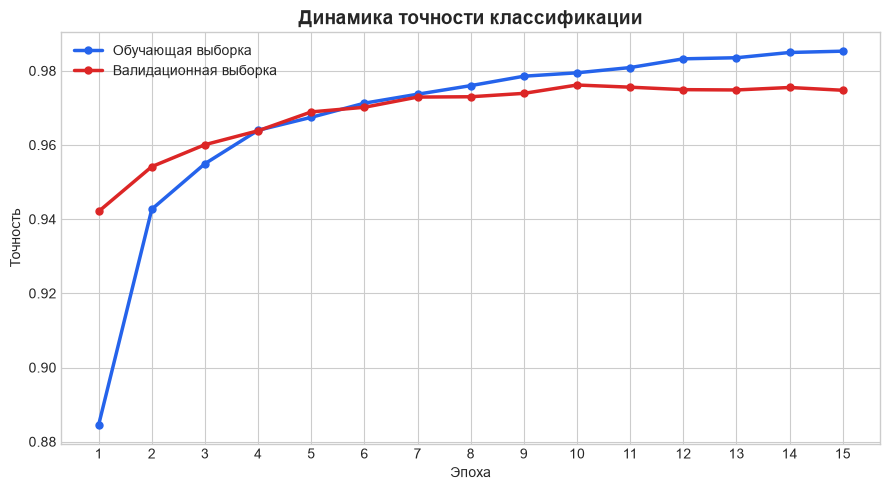

In [46]:
epochs = range(1, len(history.history["loss"]) + 1)

plt.style.use("seaborn-v0_8-whitegrid")

train_color = "#2563EB"
validation_color = "#DC2626"

# График функции потерь
plt.figure(figsize=(9, 5))
plt.plot(
    epochs,
    history.history["loss"],
    label="Обучающая выборка",
    color=train_color,
    linewidth=2.5,
    marker="o",
    markersize=5,
)
plt.plot(
    epochs,
    history.history["val_loss"],
    label="Валидационная выборка",
    color=validation_color,
    linewidth=2.5,
    marker="o",
    markersize=5,
)

plt.xlabel("Эпоха")
plt.ylabel("Функция потерь")
plt.title("Динамика функции потерь", fontsize=14, fontweight="bold")
plt.xticks(epochs)
plt.legend()
plt.tight_layout()
plt.show()


# График точности классификации
plt.figure(figsize=(9, 5))
plt.plot(
    epochs,
    history.history["accuracy"],
    label="Обучающая выборка",
    color=train_color,
    linewidth=2.5,
    marker="o",
    markersize=5,
)
plt.plot(
    epochs,
    history.history["val_accuracy"],
    label="Валидационная выборка",
    color=validation_color,
    linewidth=2.5,
    marker="o",
    markersize=5,
)

plt.xlabel("Эпоха")
plt.ylabel("Точность")
plt.title("Динамика точности классификации", fontsize=14, fontweight="bold")
plt.xticks(epochs)
plt.legend()
plt.tight_layout()
plt.show()

В процессе обучения функция потерь уменьшается, а точность классификации растёт. На первых эпохах валидационная точность выше обучающей из-за использования Dropout. После 10–11 эпох появляются небольшие признаки переобучения, однако в целом модель сохраняет высокое качество на валидационной выборке.

## Пункт 4. Проверка на тестовой выборке

Тестовая выборка не использовалась при обучении и настройке модели. Она применяется для независимой оценки качества уже обученной нейронной сети.

In [47]:
test_loss, test_acc = base_model.evaluate(x_test, y_test, verbose=0)

print(f"Test loss: {test_loss:.6f}")
print(f"Test accuracy: {test_acc:.6f}")

Test loss: 0.079986
Test accuracy: 0.977300


In [48]:
# Получаем вероятности принадлежности к каждому из 10 классов
y_pred_probs = base_model.predict(x_test, verbose=0)

# Класс с максимальной вероятностью
y_pred = np.argmax(y_pred_probs, axis=1)

cm = confusion_matrix(y_test, y_pred)

cm_accuracy = np.trace(cm) / np.sum(cm)

print(f"Accuracy по confusion matrix: {cm_accuracy:.6f}")
print(f"Accuracy из evaluate:         {test_acc:.6f}")
print(f"Разница:                      {abs(cm_accuracy - test_acc):.10f}")

Accuracy по confusion matrix: 0.977300
Accuracy из evaluate:         0.977300
Разница:                      0.0000000117


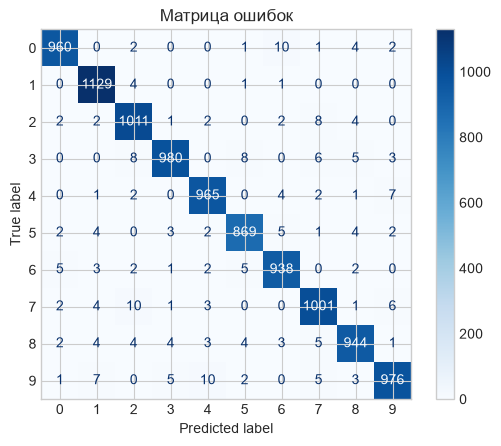

In [49]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=np.arange(10),
)

disp.plot(cmap=plt.cm.Blues, values_format="d")
plt.title("Матрица ошибок")
plt.show()

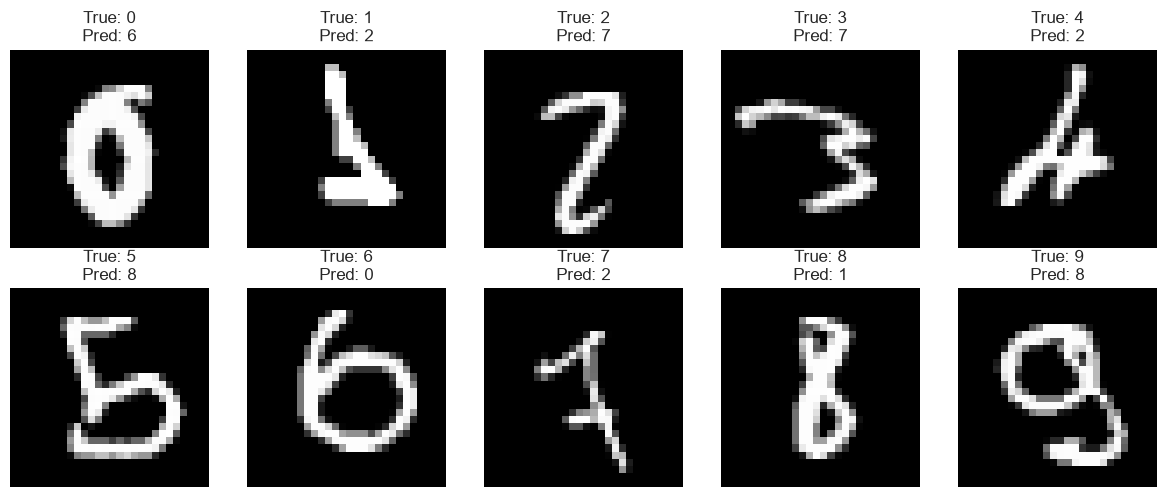

Классов с найденными ошибками: 10


In [50]:
# По одному неверно классифицированному изображению каждого истинного класса
plt.figure(figsize=(12, 5))

shown = 0

for digit in range(10):
    wrong_indices = np.where((y_test == digit) & (y_pred != digit))[0]

    if len(wrong_indices) == 0:
        continue

    index = wrong_indices[0]
    shown += 1

    plt.subplot(2, 5, digit + 1)
    plt.imshow(x_test[index].reshape(28, 28), cmap="gray")
    plt.title(f"True: {y_test[index]}\nPred: {y_pred[index]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

print("Классов с найденными ошибками:", shown)

По результатам проверки модель показывает высокую точность на тестовой выборке. Значение `accuracy`, рассчитанное через confusion matrix, совпадает с результатом `evaluate()`, что подтверждает корректность оценки качества модели. Матрица ошибок также позволяет определить, какие классы сеть чаще всего путает между собой.

## Пункт 5. Влияние dropout и batch size

Сначала зафиксируем `batch_size = 64` и исследуем влияние параметра Dropout при значениях:

`dropout = 0, 0.1, 0.2, 0.3`.

Для сравнительного эксперимента каждую модель будем обучать в течение **10 эпох**.

In [51]:
dropout_values = [0.0, 0.1, 0.2, 0.3]
dropout_histories = {}

for dropout_rate in dropout_values:
    print(f"Dropout = {dropout_rate}")

    model_temp = build_model(
        hidden_units=(96,),
        dropout_rate=dropout_rate,
    )

    model_temp.compile(
        optimizer="adam",
        loss=SparseCategoricalCrossentropy(),
        metrics=["accuracy"],
    )

    hist = model_temp.fit(
        x_train,
        y_train,
        validation_data=(x_val, y_val),
        epochs=10,
        batch_size=64,
        verbose=0,
    )

    dropout_histories[dropout_rate] = hist

Dropout = 0.0
Dropout = 0.1
Dropout = 0.2
Dropout = 0.3


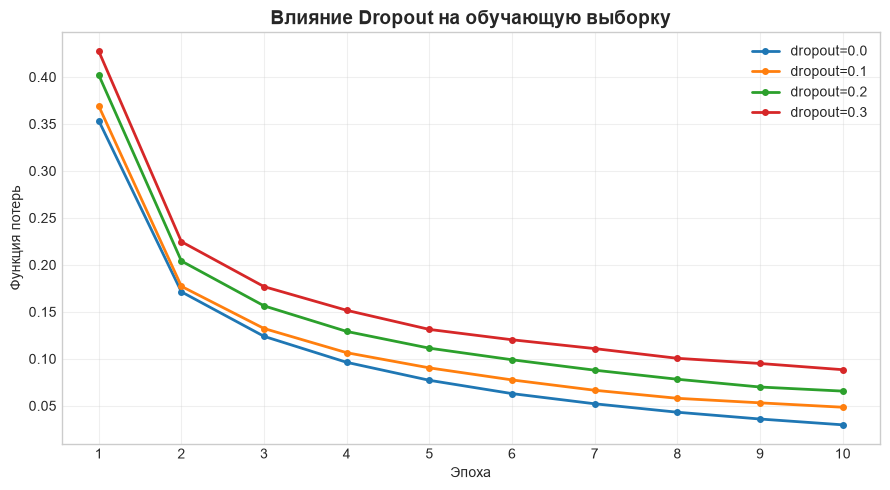

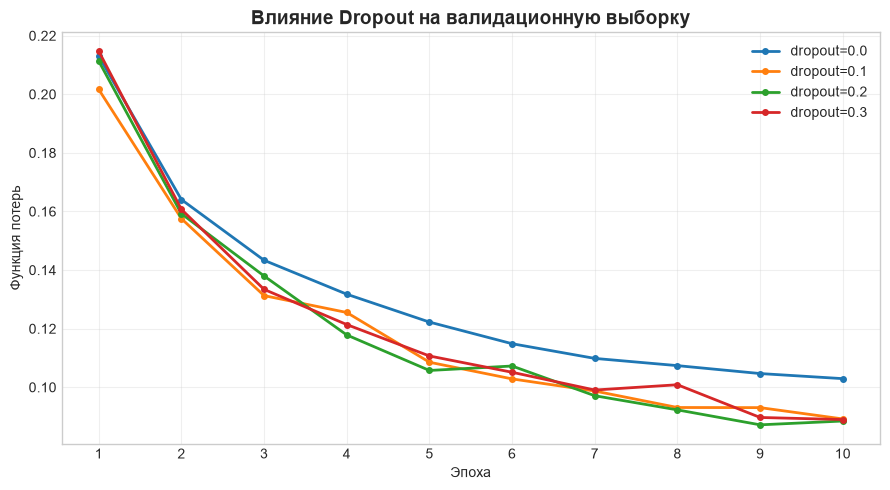

Лучший dropout по минимальному validation loss: 0.2


In [52]:
epochs = range(1, 11)

# Сравнение train loss
plt.figure(figsize=(9, 5))

for rate, hist in dropout_histories.items():
    plt.plot(
        epochs,
        hist.history["loss"],
        linewidth=2,
        marker="o",
        markersize=4,
        label=f"dropout={rate}",
    )

plt.xlabel("Эпоха")
plt.ylabel("Функция потерь")
plt.title("Влияние Dropout на обучающую выборку", fontsize=14, fontweight="bold")
plt.xticks(epochs)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


# Сравнение validation loss
plt.figure(figsize=(9, 5))

for rate, hist in dropout_histories.items():
    plt.plot(
        epochs,
        hist.history["val_loss"],
        linewidth=2,
        marker="o",
        markersize=4,
        label=f"dropout={rate}",
    )

plt.xlabel("Эпоха")
plt.ylabel("Функция потерь")
plt.title("Влияние Dropout на валидационную выборку", fontsize=14, fontweight="bold")
plt.xticks(epochs)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


best_dropout = min(
    dropout_histories,
    key=lambda rate: min(dropout_histories[rate].history["val_loss"]),
)

print("Лучший dropout по минимальному validation loss:", best_dropout)

Dropout уменьшает переобучение за счёт случайного отключения части нейронов во время обучения. При увеличении `dropout` ошибка на обучающей выборке растёт, так как обучение становится сложнее. На валидационной выборке лучший результат показал `dropout = 0.2`, поэтому это значение можно считать оптимальным среди исследованных.

Теперь зафиксируем `dropout = 0.2` и исследуем влияние размера пакета при значениях:

`batch_size = 16, 32, 64, 128`.

Для каждого значения `batch_size` будем обучать модель в течение **10 эпох**, сохраняя остальные параметры неизменными.

In [53]:
batch_sizes = [16, 32, 64, 128]
batch_histories = {}

for batch_size in batch_sizes:
    print(f"Batch size = {batch_size}")

    model_temp = build_model(
        hidden_units=(96,),
        dropout_rate=0.2,
    )

    model_temp.compile(
        optimizer="adam",
        loss=SparseCategoricalCrossentropy(),
        metrics=["accuracy"],
    )

    hist = model_temp.fit(
        x_train,
        y_train,
        validation_data=(x_val, y_val),
        epochs=10,
        batch_size=batch_size,
        verbose=0,
    )

    batch_histories[batch_size] = hist

Batch size = 16
Batch size = 32
Batch size = 64
Batch size = 128


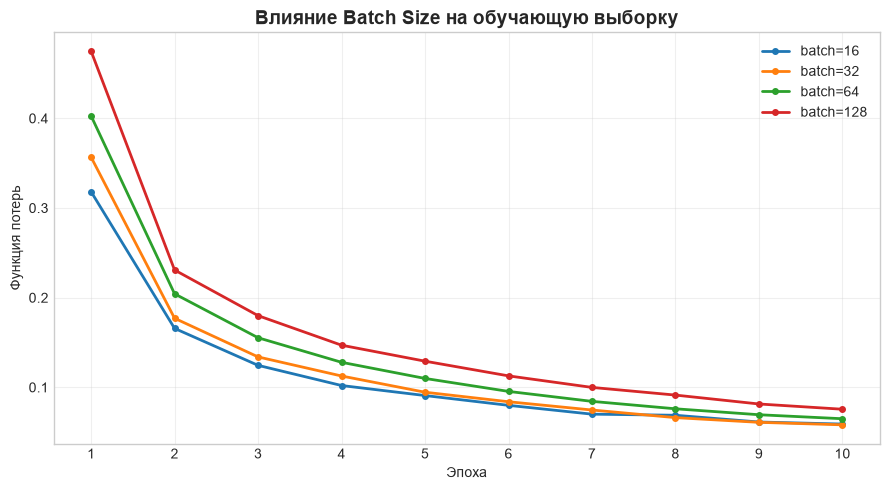

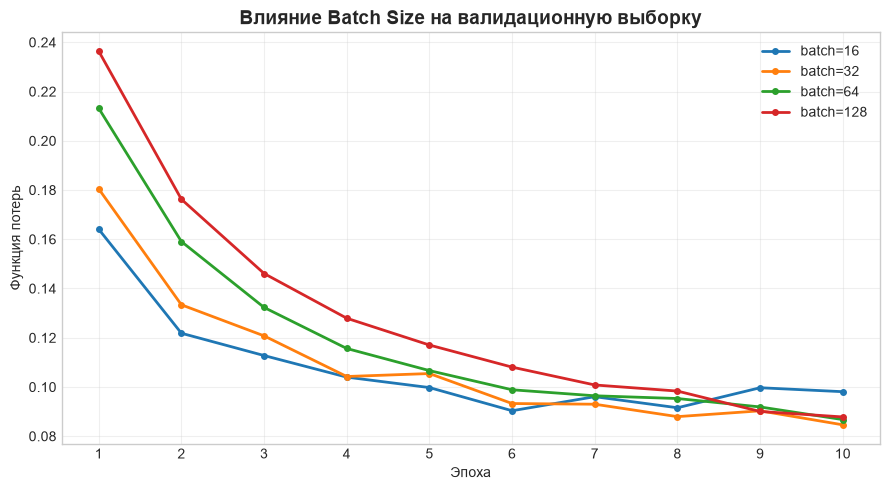

Лучший batch_size по минимальному validation loss: 32


In [54]:
epochs = range(1, 11)

# Train loss
plt.figure(figsize=(9, 5))

for batch_size, hist in batch_histories.items():
    plt.plot(
        epochs,
        hist.history["loss"],
        linewidth=2,
        marker="o",
        markersize=4,
        label=f"batch={batch_size}",
    )

plt.xlabel("Эпоха")
plt.ylabel("Функция потерь")
plt.title("Влияние Batch Size на обучающую выборку", fontsize=14, fontweight="bold")
plt.xticks(epochs)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


# Validation loss
plt.figure(figsize=(9, 5))

for batch_size, hist in batch_histories.items():
    plt.plot(
        epochs,
        hist.history["val_loss"],
        linewidth=2,
        marker="o",
        markersize=4,
        label=f"batch={batch_size}",
    )

plt.xlabel("Эпоха")
plt.ylabel("Функция потерь")
plt.title("Влияние Batch Size на валидационную выборку", fontsize=14, fontweight="bold")
plt.xticks(epochs)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


best_batch = min(
    batch_histories,
    key=lambda batch_size: min(
        batch_histories[batch_size].history["val_loss"]
    ),
)

print("Лучший batch_size по минимальному validation loss:", best_batch)

При увеличении `batch_size` количество обновлений весов за эпоху уменьшается. В проведённом эксперименте наименьшее значение `validation loss` показал `batch_size = 32`, поэтому среди исследованных значений он оказался наиболее эффективным.

## Пункт 6. GridSearchCV

Для нейронной сети с **одним скрытым слоем** с помощью `GridSearchCV` подберём оптимальные значения:

- количества нейронов в скрытом слое;
- `batch_size`.

Для сокращения времени вычислений используем небольшую сетку параметров и **3-fold cross-validation**.

In [55]:
def build_grid_model(neurons=96):
    model = Sequential([
        Input(shape=(input_size,)),
        Dense(neurons, activation="relu"),
        Dropout(0.2),
        Dense(NUM_CLASSES, activation="softmax"),
    ])

    model.compile(
        optimizer="adam",
        loss=SparseCategoricalCrossentropy(),
        metrics=["accuracy"],
    )

    return model


classifier = KerasClassifier(
    model=build_grid_model,
    epochs=8,
    verbose=0,
    random_state=RANDOM_SEED,
)

param_grid = {
    "model__neurons": [64, 96, 128],
    "batch_size": [32, 64],
}

grid = GridSearchCV(
    estimator=classifier,
    param_grid=param_grid,
    cv=3,
    scoring="accuracy",
    n_jobs=1,
)

grid_result = grid.fit(x_train, y_train)

print("Лучший результат:", grid_result.best_score_)
print("Лучшие параметры:", grid_result.best_params_)

Лучший результат: 0.9706250000000001
Лучшие параметры: {'batch_size': 32, 'model__neurons': 128}


По результатам `GridSearchCV` наилучшая средняя точность кросс-валидации составила **0.9706**. Лучший результат показала модель со **128 нейронами** в скрытом слое и `batch_size = 32`. Эти значения можно считать оптимальными среди исследованных комбинаций параметров.

# Пункт 7. Сравнение сетей с одним и двумя скрытыми слоями

Для корректного сравнения архитектур выберем сети с примерно одинаковым числом обучаемых параметров.

## Аналитический расчёт числа параметров

Для полносвязного слоя `Dense` число обучаемых параметров определяется по формуле:

$$
N_{\text{params}} = N_{\text{in}} \cdot N_{\text{out}} + N_{\text{out}}
$$

где:

- $N_{\text{in}}$ — число входов слоя;
- $N_{\text{out}}$ — число нейронов слоя;
- последнее слагаемое $N_{\text{out}}$ соответствует параметрам смещения `bias`.

### Сеть с одним скрытым слоем

Пусть скрытый слой содержит $h$ нейронов.

Число параметров между входным и скрытым слоями:

$$
784h + h
$$

Число параметров между скрытым и выходным слоями:

$$
10h + 10
$$

Общее число параметров:

$$
P_1(h) = (784h + h) + (10h + 10)
$$

После упрощения:

$$
\boxed{P_1(h) = 795h + 10}
$$

### Сеть с двумя скрытыми слоями

Пусть первый скрытый слой содержит $h_1$ нейронов, а второй — $h_2$.

Общее число обучаемых параметров:

$$
P_2(h_1,h_2)
=
(784h_1 + h_1)
+
(h_1h_2 + h_2)
+
(10h_2 + 10)
$$

После упрощения:

$$
\boxed{P_2(h_1,h_2)=785h_1+h_1h_2+11h_2+10}
$$

Слой `Dropout` обучаемых параметров не содержит.

## Выбор архитектур

Для сравнения выберем:

- **1 скрытый слой:** $h = 110$;
- **2 скрытых слоя:** $h_1 = 100$, $h_2 = 80$.

Для сети с одним скрытым слоем:

$$
P_1(110)=795 \cdot 110+10=87\,460
$$

Для сети с двумя скрытыми слоями:

$$
P_2(100,80)
=
785 \cdot 100
+
100 \cdot 80
+
11 \cdot 80
+
10
=
87\,390
$$

Разница между моделями:

$$
87\,460-87\,390=70
$$

обучаемых параметров.

Таким образом, обе модели имеют практически одинаковое число обучаемых параметров, что позволяет корректно сравнить влияние количества скрытых слоёв на качество обучения.

In [56]:
model_1_hidden = build_model(
    hidden_units=(110,),
    dropout_rate=0.0,
)

model_2_hidden = build_model(
    hidden_units=(100, 80),
    dropout_rate=0.0,
)

print("Модель с одним скрытым слоем:")
model_1_hidden.summary()

print("\nМодель с двумя скрытыми слоями:")
model_2_hidden.summary()

Модель с одним скрытым слоем:


Model: "sequential_60"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_121 (Dense)               │ (None, 110)            │        86,350 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_122 (Dense)               │ (None, 10)             │         1,110 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 87,460 (341.64 KB)

 Trainable params: 87,460 (341.64 KB)

...

Model: "sequential_61"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_123 (Dense)               │ (None, 100)            │        78,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_124 (Dense)               │ (None, 80)             │         8,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_125 (Dense)               │ (None, 10)             │           810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 87,390 (341.37 KB)

 Trainable params: 87,390 (341.37 KB)

 Non-trainable params: 0 (0.00 B)

In [57]:
model_1_hidden.compile(
    optimizer="adam",
    loss=SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

model_2_hidden.compile(
    optimizer="adam",
    loss=SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

history_1 = model_1_hidden.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=15,
    batch_size=64,
    verbose=0,
)

history_2 = model_2_hidden.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=15,
    batch_size=64,
    verbose=0,
)

In [58]:
loss_1, acc_1 = model_1_hidden.evaluate(x_test, y_test, verbose=0)
loss_2, acc_2 = model_2_hidden.evaluate(x_test, y_test, verbose=0)

print("1 скрытый слой:")
print(f"Test loss:     {loss_1:.6f}")
print(f"Test accuracy: {acc_1:.6f}")

print("\n2 скрытых слоя:")
print(f"Test loss:     {loss_2:.6f}")
print(f"Test accuracy: {acc_2:.6f}")

print(f"\nРазница accuracy: {acc_2 - acc_1:+.6f}")

1 скрытый слой:
Test loss:     0.092060
Test accuracy: 0.976400

2 скрытых слоя:
Test loss:     0.152190
Test accuracy: 0.970400

Разница accuracy: -0.006000


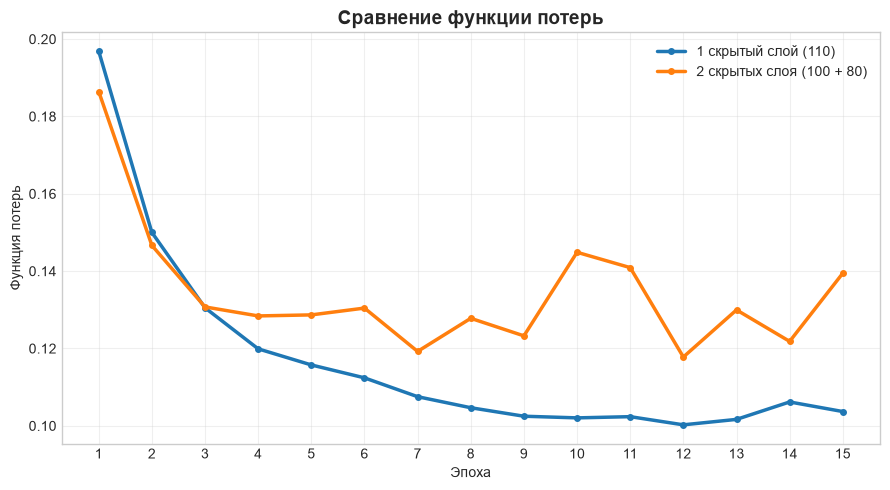

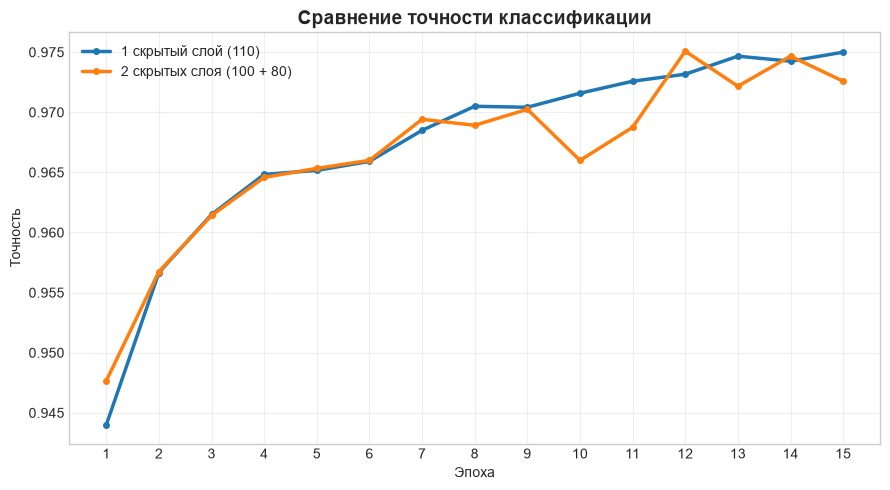

In [59]:
epochs = range(1, 16)

# Validation loss
plt.figure(figsize=(9, 5))

plt.plot(
    epochs,
    history_1.history["val_loss"],
    linewidth=2.5,
    marker="o",
    markersize=4,
    label="1 скрытый слой (110)",
)

plt.plot(
    epochs,
    history_2.history["val_loss"],
    linewidth=2.5,
    marker="o",
    markersize=4,
    label="2 скрытых слоя (100 + 80)",
)

plt.xlabel("Эпоха")
plt.ylabel("Функция потерь")
plt.title("Сравнение функции потерь", fontsize=14, fontweight="bold")
plt.xticks(epochs)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


# Validation accuracy
plt.figure(figsize=(9, 5))

plt.plot(
    epochs,
    history_1.history["val_accuracy"],
    linewidth=2.5,
    marker="o",
    markersize=4,
    label="1 скрытый слой (110)",
)

plt.plot(
    epochs,
    history_2.history["val_accuracy"],
    linewidth=2.5,
    marker="o",
    markersize=4,
    label="2 скрытых слоя (100 + 80)",
)

plt.xlabel("Эпоха")
plt.ylabel("Точность")
plt.title("Сравнение точности классификации", fontsize=14, fontweight="bold")
plt.xticks(epochs)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

При практически одинаковом числе обучаемых параметров модель с одним скрытым слоем показала более высокую точность и меньшую функцию потерь на тестовой выборке. Сеть с двумя скрытыми слоями обучалась менее стабильно и не дала улучшения качества. Таким образом, в данном эксперименте увеличение глубины сети оказалось неэффективным.

# Итог по лабораторной работе

В ходе лабораторной работы была построена и обучена полносвязная нейронная сеть для классификации рукописных цифр MNIST. Базовая модель показала высокую точность классификации на валидационной и тестовой выборках.

Исследование гиперпараметров показало, что среди рассмотренных значений наилучший результат для Dropout получен при `dropout = 0.2`, а для размера пакета — при `batch_size = 32`.

С помощью `GridSearchCV` был выполнен дополнительный подбор числа нейронов и `batch_size`. Наилучшая средняя точность кросс-валидации составила **0.9706** для модели со **128 нейронами** в скрытом слое и `batch_size = 32`.

При сравнении сетей с одним и двумя скрытыми слоями при практически одинаковом числе обучаемых параметров модель с одним скрытым слоем показала более высокую точность и меньшую функцию потерь на тестовой выборке. Таким образом, в данном эксперименте увеличение глубины сети не привело к улучшению качества классификации.